# Who's That Pokémon? — Image Pair Viewer

This notebook previews original Generation 1 Pokémon images next to their silhouette versions.

In [3]:
from pathlib import Path
import random
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [5]:
DATA_DIR = Path('../data')  # change to Path('data') if running from repo root
manifest = pd.read_csv(DATA_DIR / 'manifest.csv')
pairs = manifest[(manifest['split'] == 'train') & (manifest['status'] == 'ok')]
print(f'Available train pairs: {len(pairs)}')

Available train pairs: 277


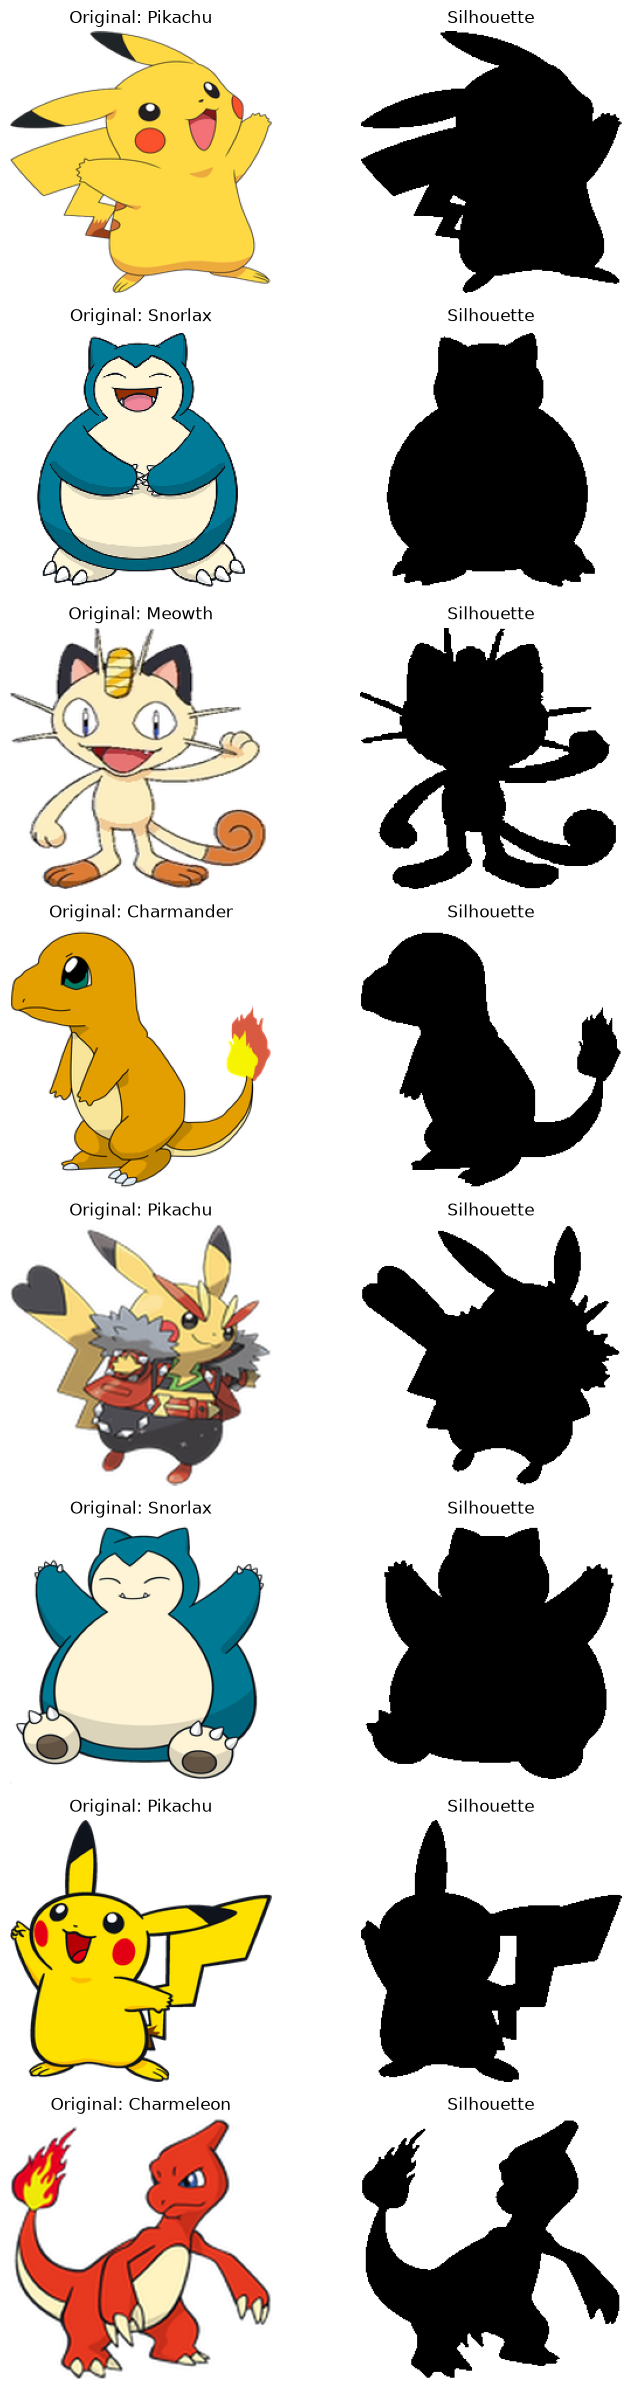

In [7]:
sample_size = 8
rows = pairs.to_dict('records')
chosen = random.sample(rows, k=min(sample_size, len(rows)))

fig, axes = plt.subplots(len(chosen), 2, figsize=(8, 3 * len(chosen)))
if len(chosen) == 1:
    axes = [axes]

for ax_pair, item in zip(axes, chosen):
    original = Image.open(DATA_DIR / item['original_path'])
    silhouette = Image.open(DATA_DIR / item['silhouette_path'])

    ax_pair[0].imshow(original)
    ax_pair[0].set_title(f"Original: {item['label']}")
    ax_pair[0].axis('off')

    ax_pair[1].imshow(silhouette)
    ax_pair[1].set_title('Silhouette')
    ax_pair[1].axis('off')

plt.tight_layout()
plt.show()